# Introduction to RKHorn

RKHorn simulates the charged pions and kaons made by the Booster Neutrino Beam (BNB): 8 GeV protons hit a beryllium target, the mesons are bent by a magnetic horn, and they decay in a 50 m pipe. This notebook walks through one small simulation from start to finish.

1. set up a simulation
2. run it and look at what it returns
3. see what the horn does
4. look at individual tracks
5. turn the mesons into a neutrino flux at a detector
6. save and reload the mesons
7. other species and antineutrino mode

Run it from the `jupyter` folder. The cells below simulate a few thousand mesons, which takes about ten seconds.

In [1]:
import os
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np

sys.path.append("..")
from constants import BR_PI_MUNU, M_P, M_PI
import flux_io
from rkhorn import ChargedPionFluxMiniBooNE, forced_detector_flux

plt.style.use(os.path.abspath("../custom.mplstyle"))
np.random.seed(1)

## 1. Set up a simulation

`ChargedPionFluxMiniBooNE` holds the whole chain: the proton beam, meson production in the target, and the horn.

| Argument | Meaning |
|---|---|
| `proton_energy` | total proton energy in MeV; the BNB momentum is 8.89 GeV/c |
| `meson_species` | `"pi_plus"`, `"pi_minus"` or `"k_plus"`; this sets the charge, mass and lifetime |
| `horn_current` | in kA; positive focuses positive mesons (neutrino mode), negative focuses negative mesons |
| `n_samples` | number of Monte Carlo mesons |
| `n_pot` | protons on target the weights are normalized to; use 1 to get "per POT" |
| `absorption` | hadronic absorption in the target and horn: `"reaction"` (default), `"inelastic"` or `None` |
| `step_size_ns` | tracking time step, 0.1 ns by default |

In [2]:
P_BEAM = 8.89e3
sim = ChargedPionFluxMiniBooNE(
    proton_energy=np.sqrt(P_BEAM**2 + M_P**2), meson_species="pi_plus",
    horn_current=174.0, n_samples=4000, n_pot=1)

## 2. Run it

`simulate()` does three things: it draws where each proton reacts in the target, it draws the momentum and angle of each meson from the production cross section, and it tracks each meson through the target and the horn field until it decays or leaves the horn. Mesons that leave the horn fly straight to a random decay point.

Mesons are sampled uniformly in momentum and angle, so each one carries a weight. The sum of the weights is the number of mesons per POT. `theta_max` limits the production angle that is sampled; mesons made at wider angles than 0.6 rad do not reach a detector on the beam axis.

In [3]:
sim.simulate(theta_max=0.6)

  0%|          | 0/4000 [00:00<?, ?it/s]

  2%|▏         | 88/4000 [00:00<00:04, 871.36it/s]

  4%|▍         | 180/4000 [00:00<00:04, 891.81it/s]

  7%|▋         | 270/4000 [00:00<00:04, 893.15it/s]

  9%|▉         | 360/4000 [00:00<00:04, 863.16it/s]

 11%|█         | 447/4000 [00:00<00:04, 864.02it/s]

... (36 outputs left out)

 94%|█████████▍| 3774/4000 [00:04<00:00, 902.75it/s]

 97%|█████████▋| 3865/4000 [00:04<00:00, 861.83it/s]

 99%|█████████▉| 3952/4000 [00:04<00:00, 854.77it/s]

100%|██████████| 4000/4000 [00:04<00:00, 869.04it/s]

The mesons at production are in `sim.meson_flux_pre_horn`, one row per meson: momentum [MeV], angle to the beam axis [rad], weight.

The mesons after the horn are in `sim.decayed_flux_array()`, one row per meson with eight columns:

| Column | Quantity |
|---|---|
| 0 | momentum at decay [MeV] |
| 1 | angle to the beam axis at decay [rad] |
| 2, 3, 4 | decay position x, y, z [m]; z is measured from the upstream face of the target |
| 5 | 1 if the decay happens in the open beamline, 0 if the meson hit the collimator, the pipe wall or the beam stop first |
| 6 | weight [mesons per POT], after absorption in material |
| 7 | azimuthal angle of the momentum at decay [rad] |

In [4]:
produced = sim.meson_flux_pre_horn
decayed = sim.decayed_flux_array()
in_beamline = decayed[:, 5] > 0.0

print("first rows at production: p [MeV], theta [rad], weight")
print(produced[:3])
print(f"\npi+ produced per POT (sampled range): {produced[:, 2].sum():.3f}")
print(f"pi+ after absorption:                 {decayed[:, 6].sum():.3f}")
print(f"pi+ decaying in the open beamline:    "
      f"{decayed[in_beamline, 6].sum():.3f}")

first rows at production: p [MeV], theta [rad], weight
[[1.04641948e+03 3.05722007e-01 6.89379989e-04]
 [6.77653438e+02 1.09724584e-01 4.57849752e-04]
 [4.95450260e+03 2.32606195e-01 3.11804347e-06]]

pi+ produced per POT (sampled range): 0.564
pi+ after absorption:                 0.502
pi+ decaying in the open beamline:    0.117


## 3. What the horn does

The horn bends positive mesons towards the beam axis. Compare the angle to the axis at production and after the horn. The momentum changes only through energy loss in the target and the horn conductor.

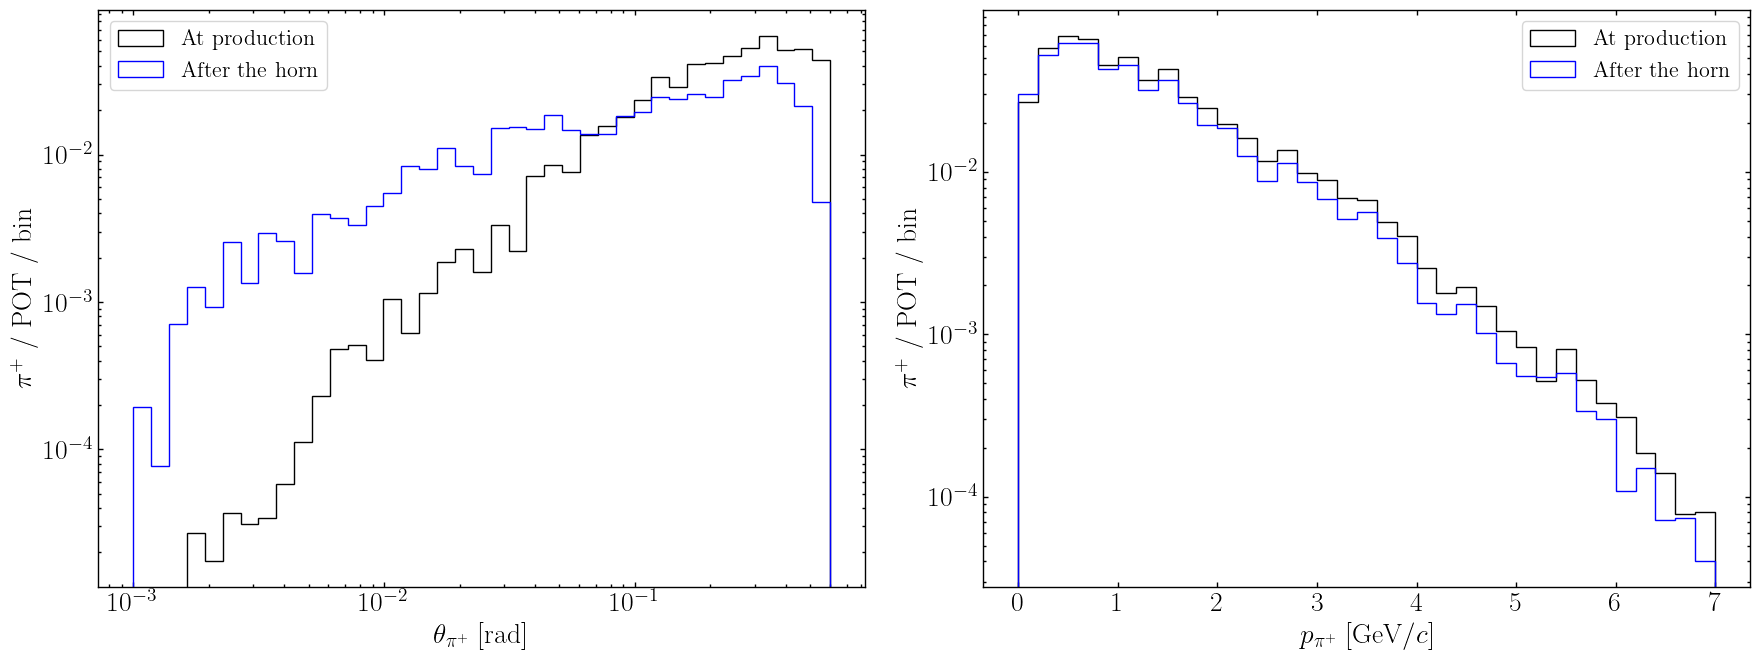

In [5]:
theta_edges = np.logspace(-3, np.log10(0.6), 40)
p_edges = np.linspace(0.0, 7.0, 36)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].hist(produced[:, 1], weights=produced[:, 2], bins=theta_edges,
             histtype="step", color="k", label="At production")
axes[0].hist(decayed[:, 1], weights=decayed[:, 6], bins=theta_edges,
             histtype="step", color="b", label="After the horn")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel(r"$\theta_{\pi^+}$ [rad]")
axes[0].set_ylabel(r"$\pi^+$ / POT / bin")
axes[0].legend(loc="upper left")

axes[1].hist(produced[:, 0]*1.0e-3, weights=produced[:, 2], bins=p_edges,
             histtype="step", color="k", label="At production")
axes[1].hist(decayed[:, 0]*1.0e-3, weights=decayed[:, 6], bins=p_edges,
             histtype="step", color="b", label="After the horn")
axes[1].set_yscale("log")
axes[1].set_xlabel(r"$p_{\pi^+}$ [GeV$/c$]")
axes[1].set_ylabel(r"$\pi^+$ / POT / bin")
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Individual tracks

`simulate_with_histories()` keeps the position of every meson at every time step. It returns three lists (x, y, z), one entry per meson. Use it with a small number of mesons.

The horn outline comes from the tracker, `sim.rksolver`: `inner_radius(z)` is the outer radius of the inner conductor, and the field fills the space between it and the outer conductor at 30 cm.

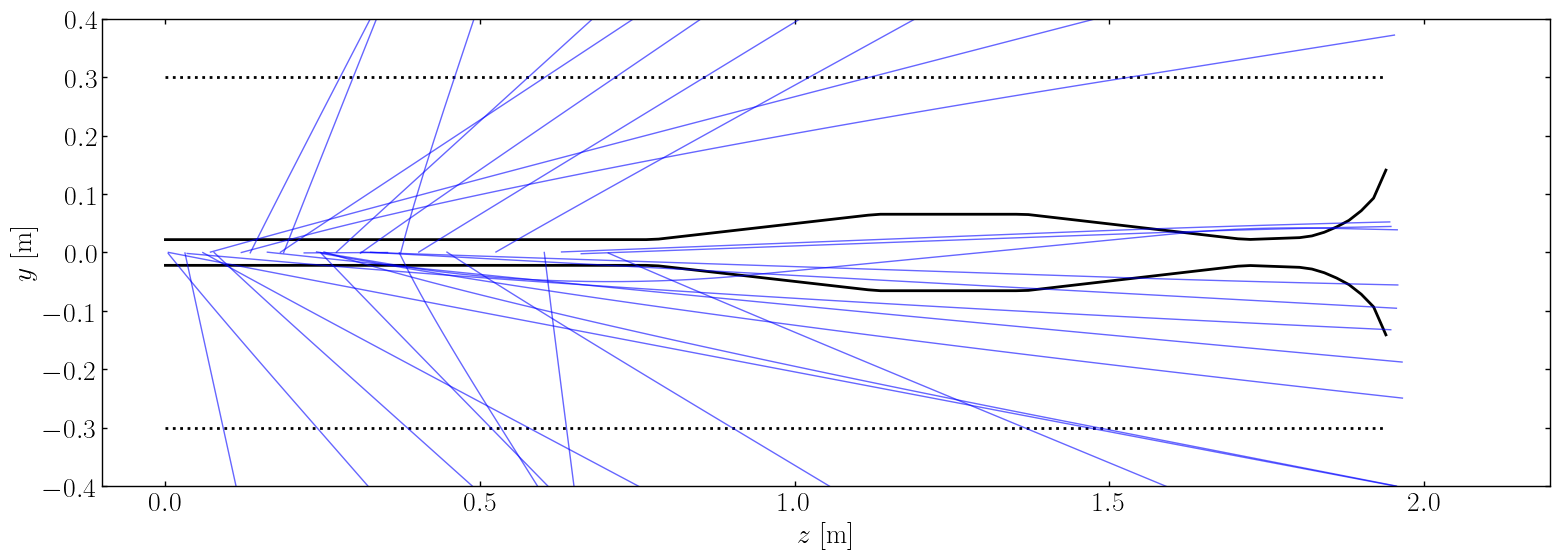

In [6]:
sim_tracks = ChargedPionFluxMiniBooNE(
    proton_energy=np.sqrt(P_BEAM**2 + M_P**2), meson_species="pi_plus",
    horn_current=174.0, n_samples=30, n_pot=1)
xs, ys, zs = sim_tracks.simulate_with_histories()

solver = sim_tracks.rksolver
z_horn = np.linspace(solver.horn_start, solver.horn_end, 100)

fig, ax = plt.subplots(figsize=(16, 6))
for sign in (1.0, -1.0):
    ax.plot(z_horn, sign*solver.inner_radius(z_horn), color="k")
    ax.plot([solver.horn_start, solver.horn_end],
            [sign*solver.horn_max_radius]*2, color="k", linestyle="dotted")
for y, z in zip(ys, zs):
    ax.plot(z, y, color="b", linewidth=1, alpha=0.6)
ax.set_xlim(-0.1, 2.2)
ax.set_ylim(-0.4, 0.4)
ax.set_xlabel(r"$z$ [m]")
ax.set_ylabel(r"$y$ [m]")
fig.tight_layout()
plt.show()

## 5. Neutrino flux at a detector

`forced_detector_flux` takes the table of decayed mesons and returns, for each meson, the energy of the neutrino from $\pi^+ \to \mu^+ \nu_\mu$ that points at the detector and its contribution to the flux there in $\nu$ / cm$^2$ / POT. No random decay direction is thrown, so every meson counts.

The detector position is `det_pos`, in meters, in the same frame as the decay positions. The default is MiniBooNE, 541 m downstream on the beam axis. Pass only the mesons that decay in the open beamline.

nu_mu flux at MiniBooNE: 6.57e-10 nu / cm^2 / POT


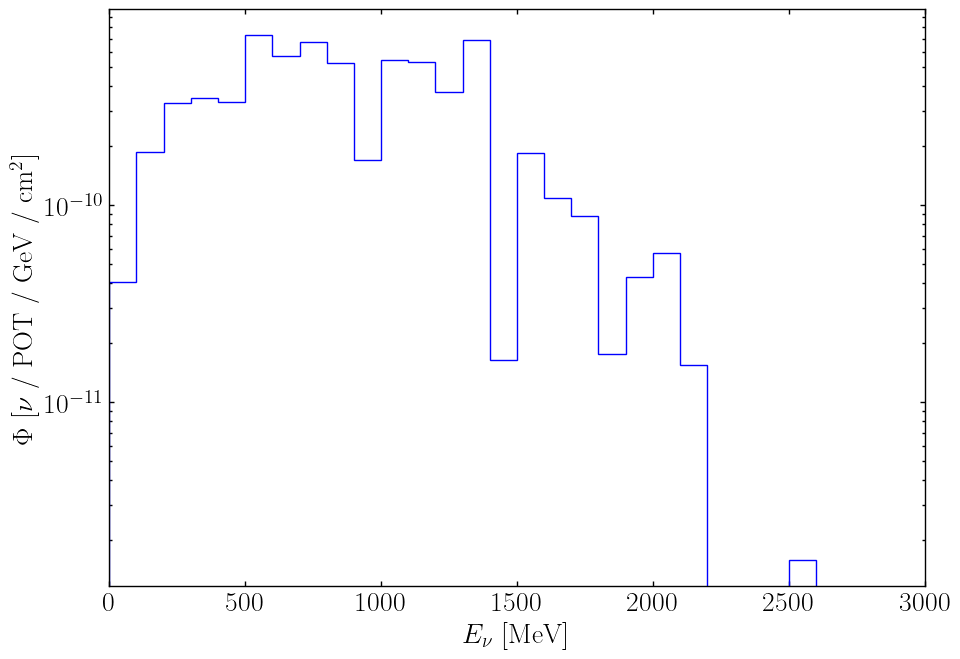

In [7]:
e_nu, flux = forced_detector_flux(decayed[in_beamline], m_meson=M_PI,
                                  br=BR_PI_MUNU, det_pos=(0.0, 0.0, 541.0))
print(f"nu_mu flux at MiniBooNE: {flux.sum():.2e} nu / cm^2 / POT")

e_edges = np.linspace(0.0, 3000.0, 31)
fig, ax = plt.subplots(figsize=(10, 7))
ax.hist(e_nu, weights=flux/0.1, bins=e_edges, histtype="step", color="b")
ax.set_yscale("log")
ax.set_xlim(e_edges[0], e_edges[-1])
ax.set_xlabel(r"$E_\nu$ [MeV]")
ax.set_ylabel(r"$\Phi$ [$\nu$ / POT / GeV / cm$^2$]")
fig.tight_layout()
plt.show()

With 4000 mesons the spectrum is noisy. The published comparison uses 150000 per species; see `tests/validate_flux.py` and `paper_plots.ipynb`.

## 6. Save and reload the mesons

`sim.meson_record()` returns everything about each meson as a dictionary of arrays: the production point, momentum and weight (`x0`, `y0`, `z0`, `p0`, `theta0`, `phi0`, `weight0`), the same at decay (`p`, `theta`, `phi`, `decay_x`, `decay_y`, `decay_z`, `weight`), the flag `decay_in_volume`, and a `meta` entry that describes the run.

`flux_io` writes and reads these records as pickle files, and converts a record back to the eight-column table of section 2. A pickle keeps the mesons themselves, so decay products for any detector or decay channel can be computed later without tracking again.

In [8]:
record = sim.meson_record()
print(record["meta"])

path = os.path.join(tempfile.gettempdir(), "rkhorn_example.pkl")
flux_io.save_meson_pickle(record, path)
reloaded = flux_io.load_meson_pickle(path)
table = flux_io.flux_array(reloaded)
print(f"\n{len(reloaded['p'])} mesons reloaded, "
      f"{len(table)} decay in the open beamline")
os.remove(path)

{'species': 'pi_plus', 'horn_current_ka': 174.0, 'n_samples': 4000, 'n_pot': 1, 'p_proton_mev': 8890.0, 'p_range_gev': (0.01, 7.5), 'theta_range_rad': (0.0, 0.6), 'absorption': 'reaction', 'step_ns': 0.10000000000000002}

4000 mesons reloaded, 426 decay in the open beamline


For production runs use the script in the repository root. It runs the species in parallel and writes to `data/pickle` (and, on request, the text tables in `data/`):

```
python simulate_miniboone_meson_fluxes.py                       # pi+, K+ at +174 kA, pi- at -174 kA
python simulate_miniboone_meson_fluxes.py --format both         # also write the text tables
python simulate_miniboone_meson_fluxes.py --species pi_plus --horn-current 0
```

## 7. Other species and antineutrino mode

Change `meson_species`, and flip the sign of the current to focus negative mesons. For kaons pass the kaon mass and branching ratio to `forced_detector_flux` (`M_K` and `BR_K_MUNU` from `constants`).

In [9]:
sim_minus = ChargedPionFluxMiniBooNE(
    proton_energy=np.sqrt(P_BEAM**2 + M_P**2), meson_species="pi_minus",
    horn_current=-174.0, n_samples=4000, n_pot=1)
sim_minus.simulate(discard_zeros=True, theta_max=0.6)

_, flux_bar = forced_detector_flux(sim_minus.decayed_flux_array(),
                                   m_meson=M_PI, br=BR_PI_MUNU)
print(f"nu_mubar flux at MiniBooNE: {flux_bar.sum():.2e} nu / cm^2 / POT")

  0%|          | 0/4000 [00:00<?, ?it/s]

  2%|▏         | 89/4000 [00:00<00:04, 889.63it/s]

  4%|▍         | 179/4000 [00:00<00:04, 889.10it/s]

  7%|▋         | 268/4000 [00:00<00:04, 846.50it/s]

  9%|▉         | 353/4000 [00:00<00:04, 837.11it/s]

 11%|█         | 439/4000 [00:00<00:04, 843.97it/s]

... (38 outputs left out)

 97%|█████████▋| 3883/4000 [00:04<00:00, 891.59it/s]

 99%|█████████▉| 3974/4000 [00:04<00:00, 896.66it/s]

100%|██████████| 4000/4000 [00:04<00:00, 847.14it/s]

nu_mubar flux at MiniBooNE: 3.59e-10 nu / cm^2 / POT


`discard_zeros=True` drops the mesons that do not decay in the open beamline, so the table can be passed to `forced_detector_flux` directly.

## Where to go next

- `python tests/test_physics.py` runs seventeen hand-checkable tests of the field, the tracking, energy loss, decay and the flux formula.
- `python tests/validate_flux.py` compares the neutrino flux with the published MiniBooNE flux.
- `plot_fluxes.ipynb` has more plots of the saved meson samples.
- `paper_plots.ipynb` makes the figures of the paper.